# Station Time Series Clustering

In [1]:
!pip install sktime
!pip install dtaidistance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.9/36.9 MB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.5/141.5 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 17.3 MB/s eta 0:00:00


In [2]:
import pandas as pd
from google.colab import drive
import sktime
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

## Loading Data

In [3]:
drive.mount('/content/drive')
df = pd.read_csv("/content/drive/Shared drives/Time Series/divvy_data/prod/station/divvy_station_train.csv")
df.head()

Mounted at /content/drive


,date,start_station_name,start_station_id,total_rides,temp_min_c,rain_sum_mm,snowfall_sum_cm,month,dayofweek,year
0,2020-01-01,63rd St Beach,101,2,-5.5,0.0,0.0,1,2,2020
1,2020-01-01,Orleans St & Hubbard St,636,5,-5.5,0.0,0.0,1,2,2020
2,2020-01-01,Orleans St & Elm St,23,3,-5.5,0.0,0.0,1,2,2020
3,2020-01-01,Orleans St & Chestnut St (NEXT Apts),620,5,-5.5,0.0,0.0,1,2,2020
4,2020-01-01,Ogden Ave & Roosevelt Rd,434,2,-5.5,0.0,0.0,1,2,2020


In [4]:
# Load training and test data
train = pd.read_csv("/content/drive/Shared drives/Time Series/divvy_data/prod/station/divvy_station_train.csv")
test = pd.read_csv("/content/drive/Shared drives/Time Series/divvy_data/prod/station/divvy_station_test.csv")

## Data Preprocessing and EDA

In [5]:
df.loc[df["year"].isin([2020])]["start_station_name"].nunique()

691

In [6]:
df.loc[df["year"].isin([2021])]["start_station_name"].nunique()

848

In [7]:
df.loc[df["year"].isin([2022])]["start_station_name"].nunique()

1674

In [8]:
df.loc[df["year"].isin([2023])]["start_station_name"].nunique()

1592

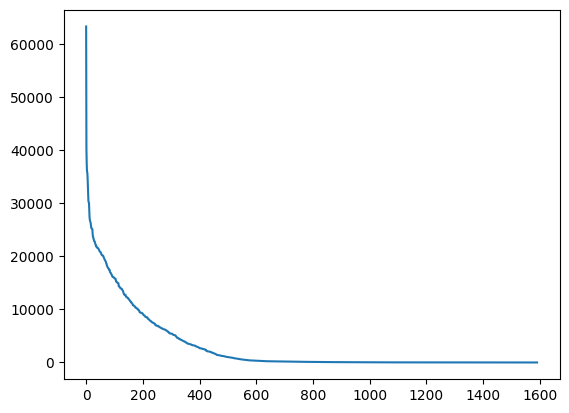

In [9]:
df_2022 = df.loc[df["year"].isin([2023])]
station_df = df_2022[["date", "start_station_name", "total_rides"]].groupby(["date", "start_station_name"]).sum().reset_index()
top_stations = station_df.groupby(["start_station_name"]).sum().sort_values("total_rides", ascending=False)
plt.plot(range(0, len(top_stations)), top_stations["total_rides"])

### Subset the number of stations needed to account for at least 50% of total rides in 2023

In [10]:
filtered_df = df.loc[df["year"].isin([2023])]

total_rides = top_stations["total_rides"].iloc[1:].sum()
indices = []
stations = []
ride_percent = 0
idx = 0

for station in top_stations.index[:501]:

    station_days = len(filtered_df.loc[filtered_df["start_station_name"] == station])
    missing_days = 365 - station_days
    if missing_days > 365 * 0.05:
        print(f"Excluded: {station} - only {station_days} days of data (missing {missing_days} days)")
    else:
        indices.append(idx)
        stations.append(station)
        if idx >= 1:
            ride_percent = top_stations["total_rides"].iloc[1:idx+1].sum() / total_rides
    idx += 1

top100 = station_df.loc[station_df["start_station_name"].isin(stations)]
top100["date"] = pd.to_datetime(top100["date"])

print(len(stations))
print(ride_percent)

Excluded: Halsted St & Fulton St - only 291 days of data (missing 74 days)
Excluded: Burnham Harbor - only 344 days of data (missing 21 days)
Excluded: Bissell St & Armitage Ave* - only 318 days of data (missing 47 days)
Excluded: Elizabeth St & Randolph St - only 306 days of data (missing 59 days)
Excluded: Lincoln Ave & Roscoe St* - only 333 days of data (missing 32 days)
Excluded: Cannon Dr & Fullerton Ave - only 346 days of data (missing 19 days)
Excluded: Green St & Randolph St* - only 318 days of data (missing 47 days)
Excluded: Noble St & Milwaukee Ave - only 275 days of data (missing 90 days)
Excluded: Museum of Science and Industry - only 344 days of data (missing 21 days)
Excluded: Lincoln Ave & Melrose St - only 175 days of data (missing 190 days)
Excluded: Fort Dearborn Dr & 31st St - only 333 days of data (missing 32 days)
Excluded: California Ave & Francis Pl - only 257 days of data (missing 108 days)
Excluded: Buckingham Fountain (Temp) - only 107 days of data (missing 2

### Interpolate missing data and normalize

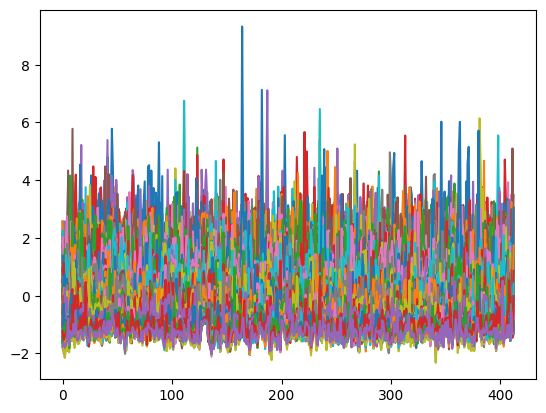

In [11]:
import numpy as np
import pandas as pd

full_dates = pd.date_range(start='2023-01-01', end='2023-12-31', freq='D')
date_df = pd.DataFrame(index=full_dates)

ts_sample = np.empty((0, 365))

for station in top100["start_station_name"].unique():
    temp_df = top100.loc[top100["start_station_name"] == station].loc[top100["date"].dt.year.isin([2023])]

    df_complete = date_df.join(temp_df.set_index('date'), how='left')

    if pd.isna(df_complete["total_rides"].iloc[0]):
        first_valid_idx = df_complete["total_rides"].first_valid_index()
        if first_valid_idx is not None:
            first_valid_value = df_complete.loc[first_valid_idx, "total_rides"]
            df_complete.loc[df_complete.index[0], "total_rides"] = first_valid_value

    if df_complete["total_rides"].isna().any():
        df_complete["total_rides"] = df_complete["total_rides"].fillna(method='ffill')
        df_complete["total_rides"] = df_complete["total_rides"].fillna(method='bfill')

    ts_sample = np.vstack([ts_sample, df_complete["total_rides"].values.reshape(1, -1)])

def z_normalize(ts_array):
    normalized = np.empty_like(ts_array, dtype=np.float64)
    for i, ts in enumerate(ts_array):
        std = np.std(ts)
        if std > 0:
            normalized[i] = (ts - np.mean(ts)) / std
        else:
            print(ts)
    return normalized

ts_normalized = z_normalize(ts_sample)

import matplotlib.pyplot as plt
plt.plot(ts_normalized)
plt.show()

### Dynamic Time Warping Example with first 2 time series observations

In [56]:
top100["start_station_name"].unique()[:2]

array(['900 W Harrison St', 'Aberdeen St & Jackson Blvd'], dtype=object)

(<Figure size 640x480 with 2 Axes>, array([<Axes: >, <Axes: >], dtype=object))

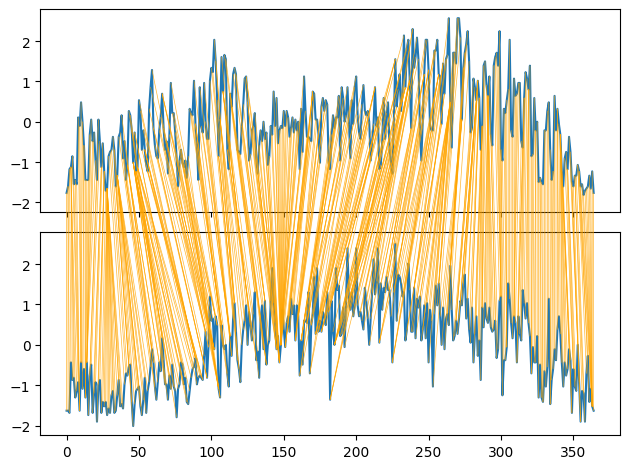

In [12]:
from dtaidistance import dtw
from dtaidistance import dtw_visualisation as dtwvis

path = dtw.warping_path(ts_normalized[0], ts_normalized[1])
dtwvis.plot_warping(ts_normalized[0], ts_normalized[1], path)

<Figure size 1200x1000 with 0 Axes>

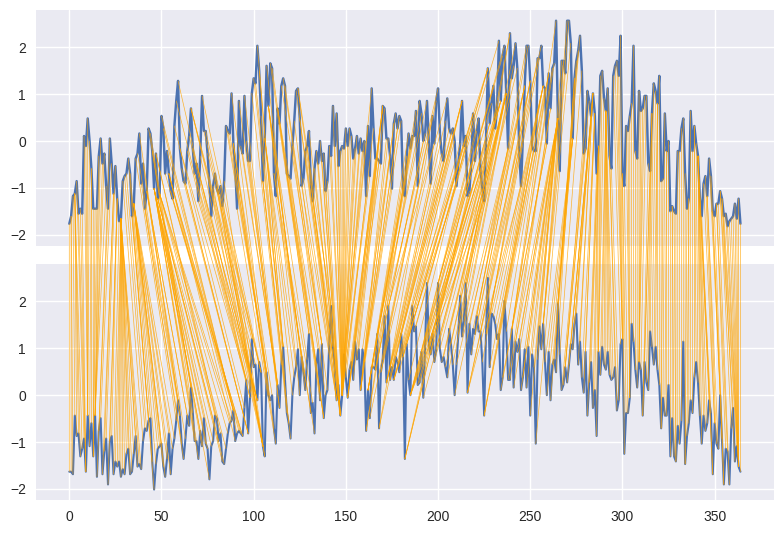

In [37]:
from dtaidistance import dtw
from dtaidistance import dtw_visualisation as dtwvis
import matplotlib.pyplot as plt
import numpy as np

# Calculate DTW path
path = dtw.warping_path(ts_normalized[0], ts_normalized[1])
distance = dtw.distance(ts_normalized[0], ts_normalized[1])

# Create a nicer figure
plt.figure(figsize=(12, 10))

# Set a clean, professional style
plt.style.use('seaborn-v0_8')

# Plot the warping path
dtwvis.plot_warping(ts_normalized[0], ts_normalized[1], path)
'''
# Enhance the current plot
# plt.title('Dynamic Time Warping Alignment', fontsize=18, fontweight='bold')
#plt.xlabel('Series 1', fontsize=14, fontweight='bold')
#plt.ylabel('Series 2', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.7)

# Add a text box with information
textstr = f'DTW Distance: {distance:.4f}\nPath Length: {len(path)}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
plt.annotate(textstr, xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12,
             bbox=props, verticalalignment='top')
'''
# Find the warping path points (markers) and enhance them
for line in plt.gca().get_lines():
    if line.get_marker() == 'o':
        line.set_markersize(8)
        line.set_markerfacecolor('red')
        line.set_markeredgecolor('black')
        line.set_markeredgewidth(1)

# Change line width and style for better visibility
for line in plt.gca().get_lines():
    if line.get_linestyle() != 'None':  # Skip marker-only "lines"
        line.set_linewidth(1.5)
        if np.array_equal(line.get_ydata(), line.get_xdata()):
            # This is likely the diagonal reference line
            line.set_linestyle(':')
            line.set_color('gray')
            line.set_linewidth(1)
            line.set_alpha(0.7)
'''
# Add a legend
plt.legend(['Series Points', 'Warping Path', 'Diagonal Reference'],
           loc='lower right', frameon=True, fancybox=True, shadow=True)
'''
# Save figure with high resolution
plt.tight_layout()
plt.savefig('enhanced_dtw_visualization.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()

## Model Building and Hyperparameter Tuning

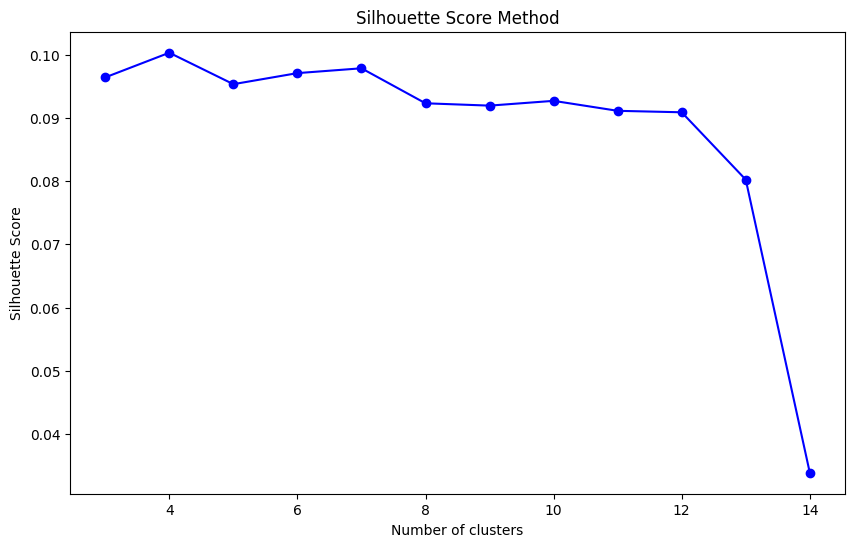

In [13]:
from sklearn.metrics import silhouette_score
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

ts_sample = ts_normalized.astype(np.double)
distance_matrix = dtw.distance_matrix_fast(ts_normalized)

distance_matrix[~np.isfinite(distance_matrix)] = np.max(distance_matrix[np.isfinite(distance_matrix)])

condensed_dist = squareform(distance_matrix)

linkage_matrix = linkage(condensed_dist, method='complete')

silhouette_scores = []
range_n_clusters = range(3, 15)

for n_clusters in range_n_clusters:
    cluster_labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    score = silhouette_score(distance_matrix, cluster_labels, metric='precomputed')
    silhouette_scores.append(score)

plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, silhouette_scores, 'b-o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Method')
plt.show()

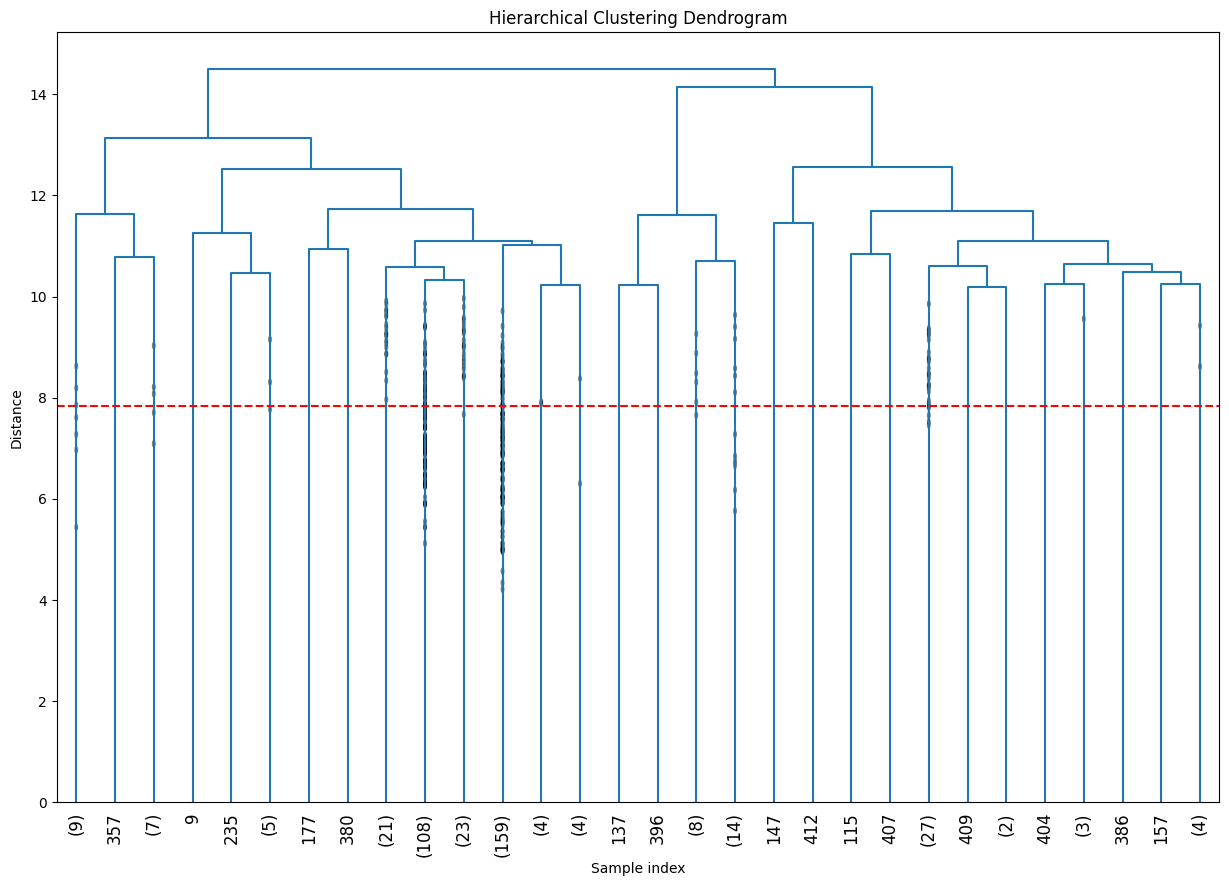

In [14]:
plt.figure(figsize=(15, 10))
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample index')
plt.ylabel('Distance')
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=12.,
    show_contracted=True,
)
plt.axhline(y=np.median(linkage_matrix[:, 2]), color='r', linestyle='--')
plt.show()

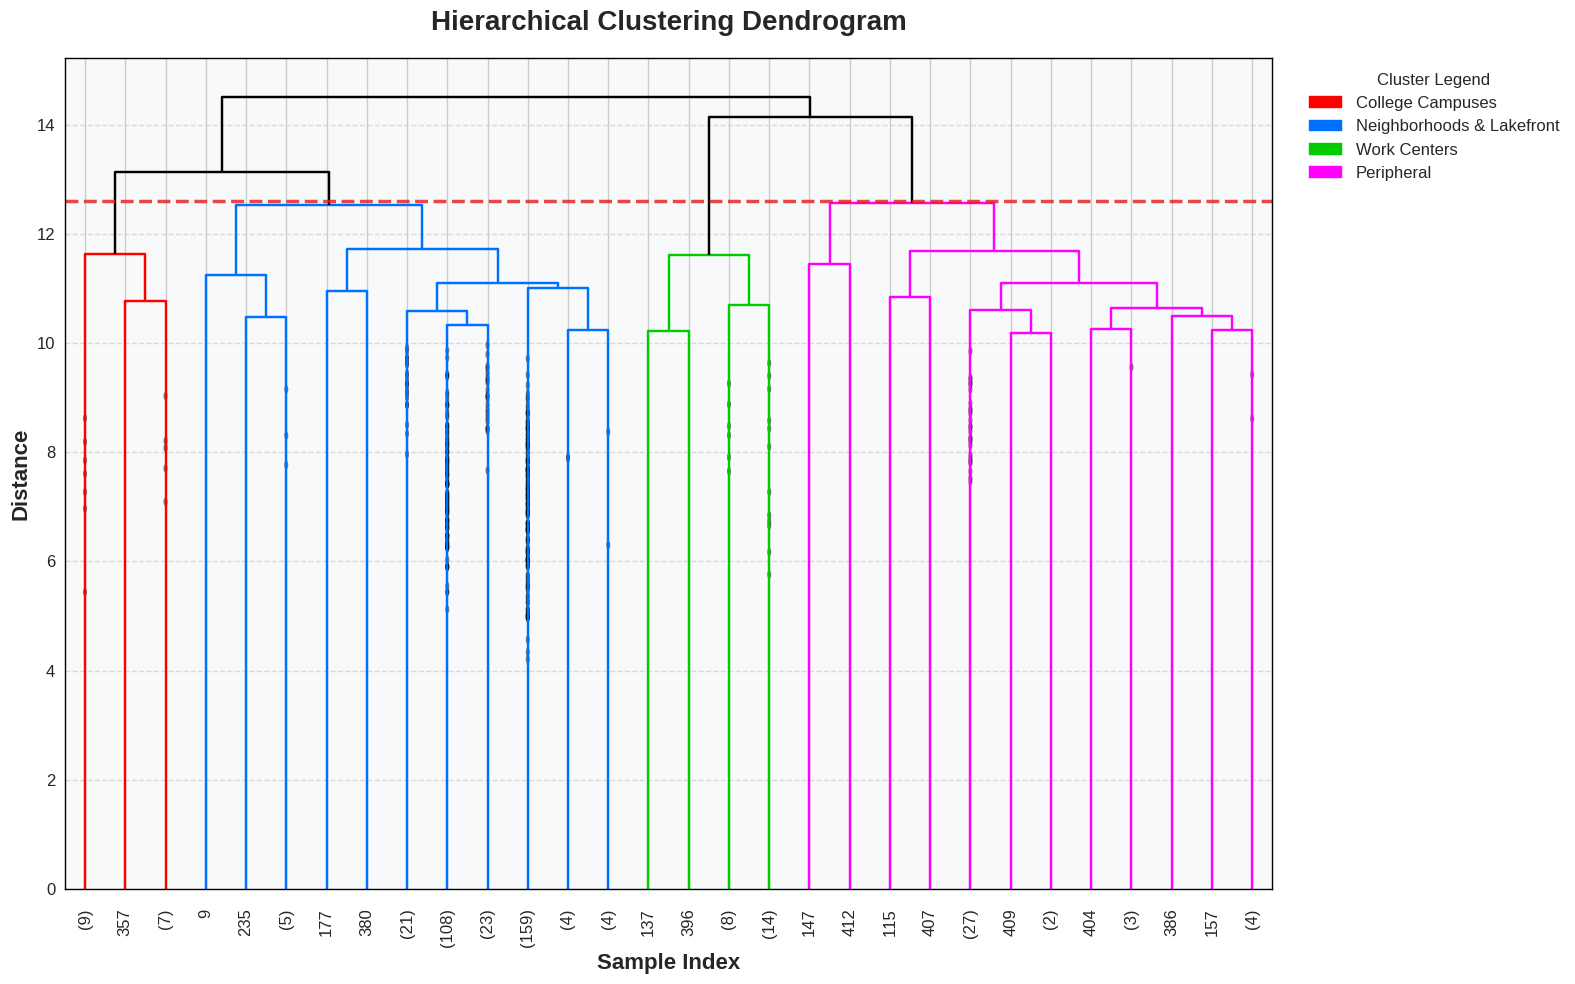

Number of clusters at threshold 12.6: 4
Cluster 1: [0, 135, 136, 138, 166, 170, 171, 172, 189, 199, 227, 259, 322, 356, 357, 403, 405]
Cluster 2: [1, 3, 5, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 77, 78, 79, 81, 82, 83, 85, 86, 87, 88, 89, 90, 91, 95, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 114, 116, 117, 118, 120, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 140, 141, 142, 143, 145, 146, 151, 152, 156, 158, 159, 160, 161, 162, 163, 164, 165, 167, 168, 169, 173, 174, 175, 176, 177, 179, 181, 182, 183, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 197, 198, 200, 201, 202, 203, 204, 206, 207, 209, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 224, 225, 228, 229, 230, 231, 232, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243,

In [81]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster import hierarchy

# Assuming linkage_matrix is already defined
# If not, you'd create it like: linkage_matrix = linkage(your_data, method='ward')

# Set a professional style
plt.style.use('seaborn-v0_8-whitegrid')

# Create a figure with better proportions and larger size for presentations
plt.figure(figsize=(16, 10))

# Set threshold as median distance
threshold = 12.6 #.562746267212471

# Create a nice-looking dendrogram
'''
dendrogram_data = dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=12.,
    show_contracted=True,
    above_threshold_color='grey',
    color_threshold=threshold,
    )
'''
hierarchy.set_link_color_palette([
    '#FF0000', '#0070FF', '#00CC00', '#FF00FF',
])
dn = dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=12.,
    show_contracted=True,
    color_threshold=threshold,
    above_threshold_color='k')

# Add custom legend matching the dendrogram colors
import matplotlib.patches as mpatches

# Get unique colors from dendrogram that are in our palette
# (excluding the above_threshold_color 'k')
used_colors = []
used_labels = []
palette = ['#FF0000', '#0070FF', '#00CC00', '#FF00FF']
# Map of colors to cluster numbers (we'll use the index in the palette)
for i, color in enumerate(palette):
    if color in dn['color_list']:
        used_colors.append(color)
        if i == 0:
            used_labels.append('College Campuses')
        elif i == 1:
            used_labels.append('Neighborhoods & Lakefront')
        elif i == 2:
            used_labels.append('Work Centers')
        else:
            used_labels.append('Peripheral')  # Or use custom labels here

# Create legend patches
legend_patches = [mpatches.Patch(color=color, label=label)
                 for color, label in zip(used_colors, used_labels)]


# Add the legend to the plot
plt.legend(handles=legend_patches,
           title='Cluster Legend',
           loc='upper right',  # You can adjust location as needed
           bbox_to_anchor=(1.25, 1),  # Adjust to prevent overlap
           fontsize=12)
# Get the current axes for further customization
ax = plt.gca()

# Calculate key values for annotations
max_height = np.max(linkage_matrix[:, 2])
min_height = np.min(linkage_matrix[:, 2])
num_samples = linkage_matrix.shape[0] + 1  # Number of original samples

# Add a horizontal line at the median distance (with styling)
plt.axhline(
    y=12.6,#.562746267212471,
    color='#E41A1C',  # A stronger red
    linestyle='--',
    linewidth=2.5,
    alpha=0.8
)

# Set better title and axis labels
plt.title('Hierarchical Clustering Dendrogram', fontsize=20, fontweight='bold', pad=20)
plt.xlabel('Sample Index', fontsize=16, fontweight='bold')
plt.ylabel('Distance', fontsize=16, fontweight='bold')

# Customize tick parameters
plt.tick_params(axis='both', which='major', labelsize=12, width=1)
for tick in ax.get_xticklabels():
    tick.set_rotation(90)
    tick.set_ha('center')

# Improve grid appearance
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)  # Place grid behind plot elements

# Add a border around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1)

# Improve x-axis visibility
ax.tick_params(axis='x', length=6, width=1, pad=8)

# Add a light background color to the plot
ax.set_facecolor('#f8f9fa')

# Adjust layout for better spacing
plt.tight_layout()

# Save the figure as a high-resolution image
plt.savefig('enhanced_dendrogram.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()
from scipy.cluster.hierarchy import fcluster

# Get cluster assignments at your threshold
cluster_assignments = fcluster(linkage_matrix, t=threshold, criterion='distance')

# Print the number of clusters formed
num_clusters = len(np.unique(cluster_assignments))
print(f"Number of clusters at threshold {threshold}: {num_clusters}")

# Create a dictionary to map cluster IDs to their member indices
cluster_members = {}
for i, cluster_id in enumerate(cluster_assignments):
    if cluster_id not in cluster_members:
        cluster_members[cluster_id] = []
    cluster_members[cluster_id].append(i)

# Print out members of each cluster
for cluster_id, members in cluster_members.items():
    print(f"Cluster {cluster_id}: {members}")

In [64]:
leaf_order = dendrogram_data['leaves']
print("Leaf order (original indices from left to right):", leaf_order)

Leaf order (original indices from left to right): [774, 357, 768, 9, 235, 787, 177, 380, 795, 790, 794, 792, 718, 740, 137, 396, 772, 785, 147, 412, 115, 407, 793, 409, 754, 404, 782, 386, 157, 791]


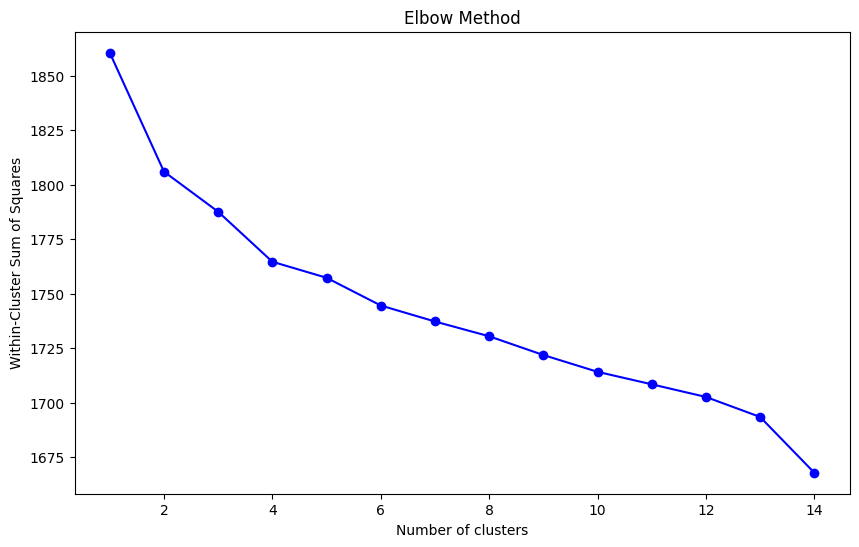

In [15]:
# Calculate WCSS for different numbers of clusters
wcss = []
range_n_clusters = range(1, 15)

for n_clusters in range_n_clusters:
    cluster_labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    current_wcss = 0

    # Calculate WCSS using DTW distances
    for i in range(1, n_clusters + 1):
        cluster_indices = np.where(cluster_labels == i)[0]
        if len(cluster_indices) > 1:
            # Get pairwise distances within this cluster
            cluster_distances = distance_matrix[np.ix_(cluster_indices, cluster_indices)]
            # Sum of squared distances to cluster center (approximated as mean of distances)
            current_wcss += np.sum(cluster_distances) / (2 * len(cluster_indices))

    wcss.append(current_wcss)

# Plot WCSS
plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, wcss, 'b-o')
plt.xlabel('Number of clusters')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Elbow Method')
plt.show()

# Optimal Model Buidling

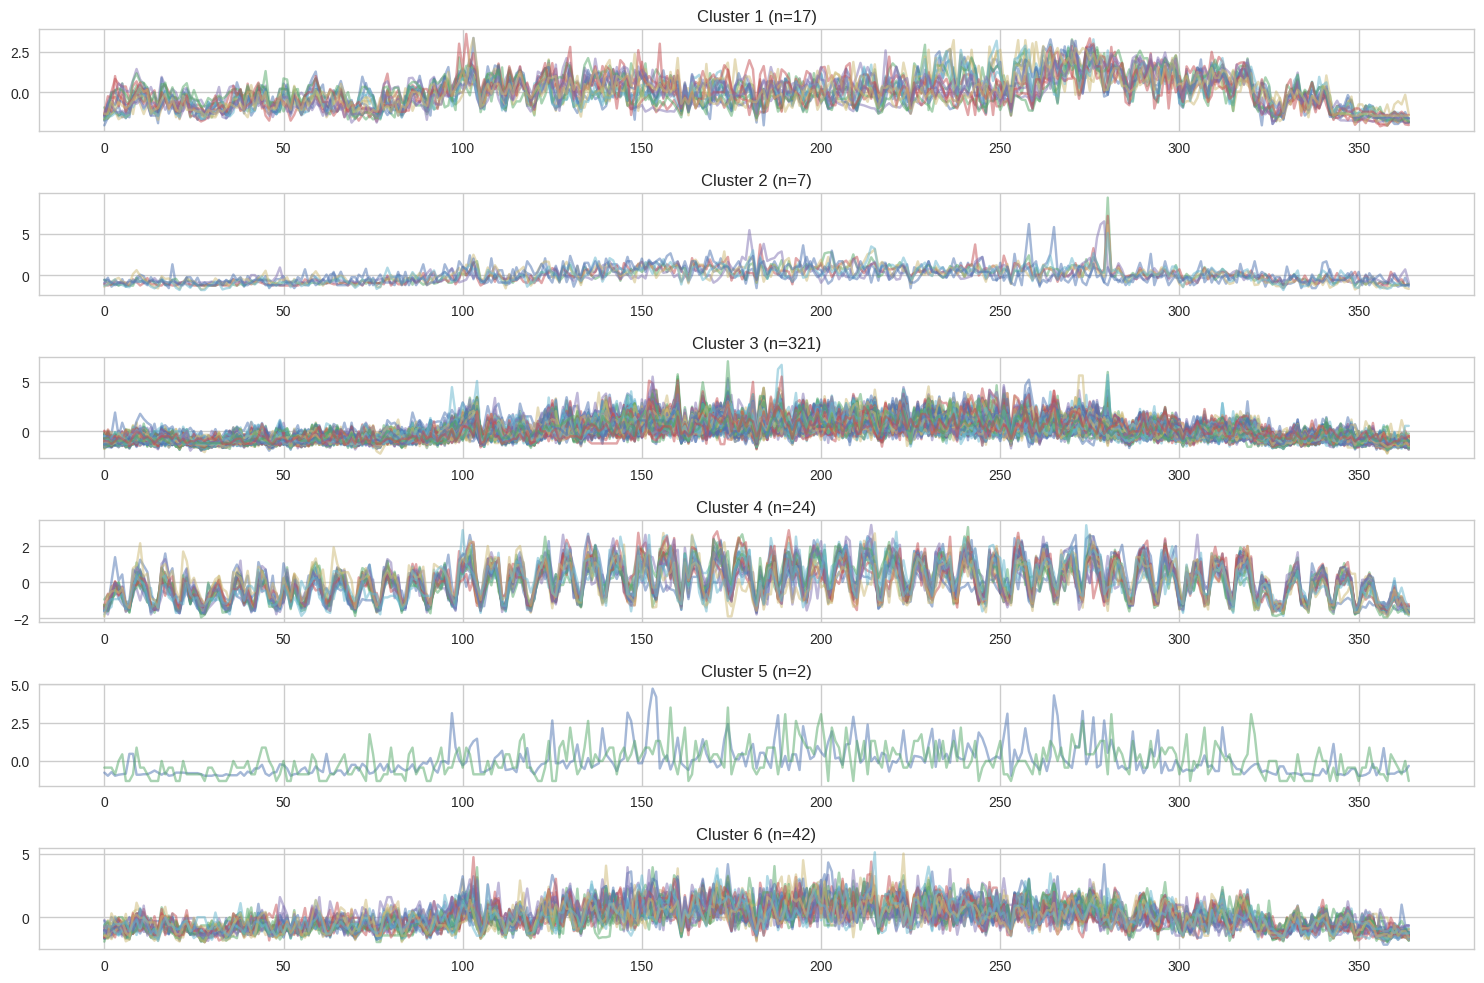

In [82]:
n_clusters = 6
cluster_labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')

# Visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))
for i in range(1, n_clusters + 1):
    cluster_members = ts_normalized[cluster_labels == i]
    plt.subplot(n_clusters, 1, i)
    plt.plot(cluster_members.T, alpha=0.5)
    plt.title(f'Cluster {i} (n={len(cluster_members)})')
plt.tight_layout()
plt.show()

In [83]:
cluster_labels[357]

1

In [84]:
cluster_labels[235]

2

In [85]:
cluster_labels[396]

4

In [86]:
cluster_labels[412]

5

In [87]:
from scipy.cluster.hierarchy import fcluster, leaders

lead_clusters = leaders(linkage_matrix, cluster_labels)
#threshold = lead_clusters[2][0]

In [88]:
n_samples = linkage_matrix.shape[0] + 1
# We want 4 clusters, so we look at row (n-4)
threshold_row = n_samples - n_clusters - 1
if threshold_row >= 0:
    threshold = linkage_matrix[threshold_row, 2]
    print(f"Threshold distance from linkage matrix: {threshold}")
else:
    print("Cannot determine threshold from linkage matrix directly as n_samples <= n_clusters")

Threshold distance from linkage matrix: 11.72548588921721


## Process and Visualize Results

In [89]:
cluster_df = pd.DataFrame({"start_station_name": top100["start_station_name"].unique(), "cluster": cluster_labels})

In [90]:
#cluster_df.to_csv("2023_cluster_df.csv")

In [19]:
expanded_df = pd.read_csv("/content/drive/Shared drives/Time Series/divvy_data/archive/full expanded/divvy_data_expanded.csv")
expanded_df.head()

,rideable_type,date,start_station_name,end_station_name,start_station_id,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,rides
0,classic_bike,2020-12-02,900 W Harrison St,Wolcott Ave & Polk St,13028,TA1309000064,41.874754,-87.649807,41.871262,-87.673688,member,1
1,classic_bike,2020-12-02,Aberdeen St & Jackson Blvd,Clinton St & Roosevelt Rd,13157,WL-008,41.877726,-87.654787,41.867118,-87.641088,member,1
2,classic_bike,2020-12-02,Albany Ave & Montrose Ave,Kedzie Ave & Milwaukee Ave,15621,13085,41.961041,-87.705866,41.929567,-87.707857,member,1
3,classic_bike,2020-12-02,Ashland Ave & 13th St,Blue Island Ave & 18th St,13354,13135,41.865234,-87.666507,41.857556,-87.661535,member,1
4,classic_bike,2020-12-02,Ashland Ave & Augusta Blvd,Ashland Ave & Augusta Blvd,13248,13248,41.899643,-87.667700,41.899643,-87.667700,casual,1


In [91]:
coordinate_df = expanded_df.loc[expanded_df["start_station_name"].isin(top100["start_station_name"].unique())].groupby(["start_station_name", "start_lat", "start_lng"]).count().reset_index()
avg_coord_df = coordinate_df.groupby("start_station_name").mean().reset_index()[["start_station_name", "start_lat", "start_lng"]]
cluster_coord_df = avg_coord_df.merge(cluster_df, on="start_station_name", how="left")

In [92]:
import pandas as pd
import folium

# Assuming your dataframe is called 'stations_df' with columns 'name', 'latitude', and 'longitude'
# If your dataframe has different column names, adjust accordingly

# Create a map centered on Chicago
chicago_coords = [41.8781, -87.6298]  # Chicago's approximate center coordinates
chicago_map = folium.Map(location=chicago_coords, zoom_start=12)

# Add markers for each station
for idx, row in cluster_coord_df.iterrows():
    folium.Marker(
        location=[row['start_lat'], row['start_lng']],
        popup=row['start_station_name'],
        tooltip=row['start_station_name']
    ).add_to(chicago_map)

# Save the map to an HTML file
chicago_map.save('chicago_divvy_stations.html')

# Display the map in a Jupyter notebook (if you're using one)
chicago_map

In [93]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster

# Assuming your dataframe is called 'stations_df' with columns 'name', 'latitude', 'longitude', and 'cluster'

# Create a map centered on Chicago
chicago_coords = [41.8781, -87.6298]
chicago_map = folium.Map(location=chicago_coords, zoom_start=12)

# Define colors for each cluster
# Using 5 distinct colors that are visually distinguishable
cluster_colors = {
    1: 'red',
    2: 'blue',
    3: 'green',
    4: 'purple',
}

# If your clusters are named differently (like 'A', 'B', 'C', etc.), adjust the dictionary keys accordingly

# Add markers for each station with color based on cluster
for idx, row in cluster_coord_df.iterrows():
    # Get the appropriate color for this cluster
    cluster_id = row['cluster']
    color = cluster_colors.get(cluster_id, 'gray')  # Default to gray if cluster not in our dictionary

    # Create a marker with the cluster-specific color
    folium.Marker(
        location=[row['start_lat'], row['start_lng']],
        popup=row['start_station_name'] + f" (Cluster: {cluster_id})",
        tooltip=row['start_station_name'],
        icon=folium.Icon(color=color)
    ).add_to(chicago_map)

# Add a legend (as a simple HTML element)
legend_html = '''
<div style="position: fixed;
     bottom: 50px; right: 50px; width: 150px; height: 160px;
     border:2px solid grey; z-index:9999; font-size:14px;
     background-color:white; padding: 10px;
     ">
     <b>Cluster Legend</b><br>
     <i class="fa fa-map-marker fa-2x" style="color:red"></i> Cluster 1<br>
     <i class="fa fa-map-marker fa-2x" style="color:blue"></i> Cluster 2<br>
     <i class="fa fa-map-marker fa-2x" style="color:green"></i> Cluster 3<br>
     <i class="fa fa-map-marker fa-2x" style="color:purple"></i> Cluster 4<br>
     <i class="fa fa-map-marker fa-2x" style="color:orange"></i> Cluster 5
</div>
'''
chicago_map.get_root().html.add_child(folium.Element(legend_html))

# Save the map to an HTML file
chicago_map.save('chicago_divvy_stations_clustered.html')

# Display the map in a Jupyter notebook (if you're using one)
chicago_map

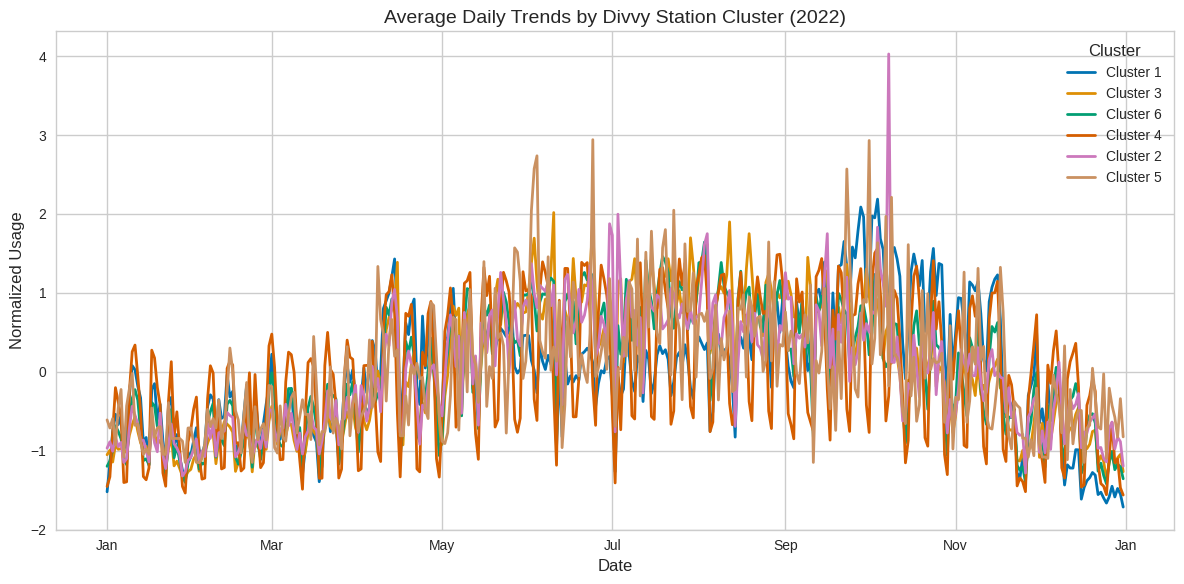

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.dates import DateFormatter
import datetime as dt

# Assuming:
# - ts_normalized is your numpy array with shape (89, 365)
# - cluster_df is your dataframe with station-to-cluster mapping

# Set up the plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("colorblind")

# 1. Generate date range for the x-axis (assuming 2022)
dates = [dt.datetime(2023, 1, 1) + dt.timedelta(days=i) for i in range(365)]

# 2. Calculate average trend for each cluster
unique_clusters = cluster_df['cluster'].unique()

# Create a figure
fig, ax = plt.subplots(figsize=(12, 6))

# For each cluster, calculate and plot the average trend
for cluster_id in unique_clusters:
    # Get indices of stations in this cluster
    station_indices = cluster_df[cluster_df['cluster'] == cluster_id].index.tolist()

    # Extract time series data for these stations
    cluster_ts = ts_normalized[station_indices, :]

    # Calculate daily average across all stations in this cluster
    cluster_avg = np.mean(cluster_ts, axis=0)

    # Plot the average trend for this cluster
    ax.plot(dates, cluster_avg, linewidth=2, label=f'Cluster {cluster_id}')

# Add labels and legend
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Normalized Usage', fontsize=12)
ax.set_title('Average Daily Trends by Divvy Station Cluster (2022)', fontsize=14)

# Format the x-axis to show months
date_form = DateFormatter("%b")
ax.xaxis.set_major_formatter(date_form)

# Add legend
ax.legend(title="Cluster")

'''
# Optional: Add annotations or vertical lines for seasons/holidays
spring_start = dt.datetime(2022, 3, 20)
summer_start = dt.datetime(2022, 6, 21)
fall_start = dt.datetime(2022, 9, 22)
winter_start = dt.datetime(2022, 12, 21)

for season_start, season_name in [
    (spring_start, 'Spring'),
    (summer_start, 'Summer'),
    (fall_start, 'Fall'),
    (winter_start, 'Winter')
]:
    ax.axvline(x=season_start, color='gray', linestyle='--', alpha=0.7)
    ax.text(season_start, ax.get_ylim()[1], f' {season_name}',
            verticalalignment='top', horizontalalignment='left', fontsize=8)
'''

plt.tight_layout()
plt.show()

In [95]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster

# Assuming your dataframe is called 'cluster_coord_df' with columns 'start_station_name', 'start_lat', 'start_lng', and 'cluster'

# Create a map centered on Chicago
chicago_coords = [41.8781, -87.6298]
chicago_map = folium.Map(location=chicago_coords, zoom_start=11)

# Define colors and custom icons for each cluster
# Using more distinct colors with higher contrast
cluster_colors = {
    1: 'red',
    2: 'blue',
    3: 'green',
    4: 'purple',
}

cluster_icons = {
    1: 'star',
    2: 'info-sign',
    3: 'ok-sign',
    4: 'flag',
}

# Create a feature group for each cluster to allow toggling on/off
cluster_groups = {i: folium.FeatureGroup(name=f"Cluster {i}") for i in range(1, 5)}

# Add markers for each station with color and icon based on cluster
for idx, row in cluster_coord_df.iterrows():
    # Get the appropriate color and icon for this cluster
    cluster_id = row['cluster']
    color = cluster_colors.get(cluster_id, 'gray')  # Default to gray if cluster not in our dictionary
    icon_type = cluster_icons.get(cluster_id, 'map-marker')

    # Create a marker with the cluster-specific color and icon
    marker = folium.Marker(
        location=[row['start_lat'], row['start_lng']],
        popup=f"<b>{row['start_station_name']}</b><br>Cluster: {cluster_id}",
        tooltip=row['start_station_name'],
        icon=folium.Icon(color=color, icon=icon_type, prefix='glyphicon')
    )

    # Add the marker to its cluster group
    marker.add_to(cluster_groups[cluster_id])

# Add all feature groups to the map
for group in cluster_groups.values():
    group.add_to(chicago_map)

# Add layer control to toggle clusters on/off
folium.LayerControl().add_to(chicago_map)

# Create a more visually appealing legend with better styling and clearer labels
legend_html = '''
<div style="position: fixed;
     bottom: 50px; right: 50px; width: 250px;
     border:2px solid grey; z-index:9999; font-size:14px;
     background-color:white; padding: 10px;
     border-radius: 5px; box-shadow: 0 0 15px rgba(0,0,0,0.2);
     ">
     <div style="text-align: center;"><b>Divvy Station Clusters</b></div>
     <hr style="margin: 10px 0px;">
     <div><i class="glyphicon glyphicon-star" style="color:red"></i> <span style="padding-left:10px;">Cluster 1 - Downtown Hub</span></div><br>
     <div><i class="glyphicon glyphicon-info-sign" style="color:blue"></i> <span style="padding-left:10px;">Cluster 2 - North Side</span></div><br>
     <div><i class="glyphicon glyphicon-ok-sign" style="color:green"></i> <span style="padding-left:10px;">Cluster 3 - West Side</span></div><br>
     <div><i class="glyphicon glyphicon-flag" style="color:purple"></i> <span style="padding-left:10px;">Cluster 4 - South Side</span></div>
</div>
'''
chicago_map.get_root().html.add_child(folium.Element(legend_html))

# Add a title to the map
title_html = '''
<div style="position: fixed;
     top: 10px; left: 50%; transform: translateX(-50%);
     z-index:9999; font-size:18px; font-weight: bold;
     background-color:white; padding: 10px;
     border-radius: 5px; box-shadow: 0 0 5px rgba(0,0,0,0.2);">
     Chicago Divvy Station Clusters
</div>
'''
chicago_map.get_root().html.add_child(folium.Element(title_html))

# Instead of HeatMap, use CircleMarkers to show density
# Create circle marker overlays for each cluster to show density
for cluster_id in range(1, 5):
    cluster_data = cluster_coord_df[cluster_coord_df['cluster'] == cluster_id]

    # Create a feature group for density visualization
    density_group = folium.FeatureGroup(name=f'Cluster {cluster_id} Density')

    # Add semi-transparent circles at each station location
    for idx, row in cluster_data.iterrows():
        folium.CircleMarker(
            location=[row['start_lat'], row['start_lng']],
            radius=25,  # Size of circle
            color=cluster_colors[cluster_id],
            fill=True,
            fill_color=cluster_colors[cluster_id],
            fill_opacity=0.2,  # Semi-transparent
            weight=1,
            opacity=0.5
        ).add_to(density_group)

    # Add the density group to the map
    density_group.add_to(chicago_map)

# Save the map to an HTML file
chicago_map.save('chicago_divvy_stations_clustered.html')

# Display the map in a Jupyter notebook (if you're using one)
chicago_map

KeyError: 6

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt
import seaborn as sns

# Assuming:
# - ts_normalized is your numpy array with shape (89, 365)
# - cluster_df is your dataframe with station-to-cluster mapping

# Set the style
plt.style.use('seaborn-v0_8-whitegrid')

# Generate date range for the x-axis (assuming 2022)
dates = [dt.datetime(2023, 1, 1) + dt.timedelta(days=i) for i in range(365)]

# Identify unique clusters and sort them
unique_clusters = sorted(cluster_df['cluster'].unique())

# Create the figure with one subplot per cluster
fig, axes = plt.subplots(len(unique_clusters), 1, figsize=(10, 2*len(unique_clusters)), sharex=True)

# Set a consistent y-axis limit for comparison
y_min, y_max = float('inf'), float('-inf')

# First pass: calculate all cluster averages and determine global y-limits
cluster_avgs = {}
for cluster_id in unique_clusters:
    # Get indices of stations in this cluster
    station_indices = cluster_df[cluster_df['cluster'] == cluster_id].index.tolist()

    # Extract time series data for these stations
    cluster_ts = ts_normalized[station_indices, :]

    # Calculate daily average across all stations in this cluster
    cluster_avg = np.mean(cluster_ts, axis=0)
    cluster_avgs[cluster_id] = cluster_avg

    # Update global y-limits
    y_min = min(y_min, np.min(cluster_avg))
    y_max = max(y_max, np.max(cluster_avg))

# Add some padding to y-limits
y_padding = (y_max - y_min) * 0.1
y_min -= y_padding
y_max += y_padding

# Second pass: plot each cluster in its own subplot
for i, cluster_id in enumerate(unique_clusters):
    ax = axes[i]
    cluster_avg = cluster_avgs[cluster_id]

    # Count stations in this cluster for the title
    station_count = sum(cluster_df['cluster'] == cluster_id)

    # Plot the average trend for this cluster
    line = ax.plot(dates, cluster_avg, linewidth=2.5, color=f'C{i}')

    # Add a filled area below the line to make it more visible
    ax.fill_between(dates, 0, cluster_avg, alpha=0.2, color=line[0].get_color())

    # Set the y-limits to be consistent across all subplots
    ax.set_ylim(y_min, y_max)

    # Set titles and labels
    ax.set_title(f'Cluster {cluster_id} (n={station_count} stations)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Normalized Usage', fontsize=10)

    # Add grid
    ax.grid(True, alpha=0.3)

    # Add year quarter markers
    for month in [4, 7, 10]:  # April, July, October
        quarter_date = dt.datetime(2023, month, 1)
        ax.axvline(x=quarter_date, color='gray', linestyle='--', alpha=0.5)
        quarter_num = ((month-1)//3) + 1
        ax.text(quarter_date, y_max - y_padding*0.5, f' Q{quarter_num}',
                verticalalignment='top', fontsize=9)

# Set up the x-axis format for the bottom subplot only
axes[-1].set_xlabel('Date', fontsize=12)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))

# Add an overall title
#fig.suptitle('Average Daily Trends by Divvy Station Cluster (2022)', fontsize=16, y=0.98)

# Adjust spacing
plt.tight_layout()
plt.subplots_adjust(top=0.95)  # Make room for the overall title

# Show the plot
plt.show()

# Optionally save the figure
# plt.savefig('divvy_cluster_faceted_trends.png', dpi=300, bbox_inches='tight')

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt
import seaborn as sns

# Assuming:
# - ts_normalized is your numpy array with shape (89, 365)
# - cluster_df is your dataframe with station-to-cluster mapping

# Set the style
plt.style.use('seaborn-v0_8-whitegrid')

# Define custom cluster colors
cluster_colors = {
    1: '#FF0000',  # Bright red
    2: '#0070FF',  # Strong blue
    3: '#00CC00',  # Bright green
    4: '#FF00FF',  # Magenta
}

# Generate date range for the x-axis (assuming 2023)
dates = [dt.datetime(2023, 1, 1) + dt.timedelta(days=i) for i in range(365)]

# Identify unique clusters and sort them
unique_clusters = sorted(cluster_df['cluster'].unique())

# Create the figure with one subplot per cluster
fig, axes = plt.subplots(len(unique_clusters), 1, figsize=(10, 2*len(unique_clusters)), sharex=True)

# Set a consistent y-axis limit for comparison
y_min, y_max = float('inf'), float('-inf')

# First pass: calculate all cluster averages and determine global y-limits
cluster_avgs = {}
for cluster_id in unique_clusters:
    # Get indices of stations in this cluster
    station_indices = cluster_df[cluster_df['cluster'] == cluster_id].index.tolist()

    # Extract time series data for these stations
    cluster_ts = ts_normalized[station_indices, :]

    # Calculate daily average across all stations in this cluster
    cluster_avg = np.mean(cluster_ts, axis=0)
    cluster_avgs[cluster_id] = cluster_avg

    # Update global y-limits
    y_min = min(y_min, np.min(cluster_avg))
    y_max = max(y_max, np.max(cluster_avg))

# Add some padding to y-limits
y_padding = (y_max - y_min) * 0.1
y_min -= y_padding
y_max += y_padding

# Second pass: plot each cluster in its own subplot
for i, cluster_id in enumerate(unique_clusters):
    ax = axes[i] if len(unique_clusters) > 1 else axes  # Handle case with single subplot
    cluster_avg = cluster_avgs[cluster_id]

    # Count stations in this cluster for the title
    station_count = sum(cluster_df['cluster'] == cluster_id)

    # Plot the average trend for this cluster using the custom color
    line = ax.plot(dates, cluster_avg, linewidth=2.5, color=cluster_colors[cluster_id])

    # Add a filled area below the line to make it more visible
    ax.fill_between(dates, 0, cluster_avg, alpha=0.2, color=cluster_colors[cluster_id])

    # Set the y-limits to be consistent across all subplots
    ax.set_ylim(y_min, y_max)

    # Set titles and labels
    if cluster_id == 1:
      ax.set_title(f'College Campuses (n={station_count} stations)', fontsize=12, fontweight='bold')
    elif cluster_id == 2:
      ax.set_title(f'Neighborhoods & Lakefront (n={station_count} stations)', fontsize=12, fontweight='bold')
    elif cluster_id == 3:
      ax.set_title(f'Work Centers (n={station_count} stations)', fontsize=12, fontweight='bold')
    else:
      ax.set_title(f'Peripheral (n={station_count} stations)', fontsize=12, fontweight='bold')

    ax.set_ylabel('Avg. Normalized Rides', fontsize=10)

    # Add grid
    ax.grid(True, alpha=0.3)

    # Add year quarter markers
    for month in [4, 7, 10]:  # April, July, October
        quarter_date = dt.datetime(2023, month, 1)
        ax.axvline(x=quarter_date, color='gray', linestyle='--', alpha=0.5)
        quarter_num = ((month-1)//3) + 1
        ax.text(quarter_date, y_max - y_padding*0.5, f' Q{quarter_num}',
                verticalalignment='top', fontsize=9)

# Set up the x-axis format for the bottom subplot only
bottom_ax = axes[-1] if len(unique_clusters) > 1 else axes
bottom_ax.set_xlabel('Date', fontsize=12)
bottom_ax.xaxis.set_major_locator(mdates.MonthLocator())
bottom_ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

# Adjust spacing
plt.tight_layout()
plt.subplots_adjust(top=0.95)  # Make room for the overall title

# Show the plot
plt.show()

In [ ]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster

# Assuming your dataframe is called 'cluster_coord_df' with columns 'start_station_name', 'start_lat', 'start_lng', and 'cluster'

# Create a map centered on Chicago
chicago_coords = [41.8781, -87.6298]
chicago_map = folium.Map(location=chicago_coords, zoom_start=11)

# Define colors for each cluster
# Using highly distinguishable colors with high contrast
cluster_colors = {
    1: '#FF0000',  # Bright red
    2: '#0070FF',  # Strong blue
    3: '#00CC00',  # Bright green
    4: '#FF00FF',  # Magenta
}

cluster_icons = {
    1: 'star',
    2: 'info-sign',
    3: 'ok-sign',
    4: 'flag',
}

# Create a feature group for each cluster to allow toggling on/off
cluster_groups = {i: folium.FeatureGroup(name=f"Cluster {i}") for i in range(1, 5)}

# Add markers for each station with color and icon based on cluster
for idx, row in cluster_coord_df.iterrows():
    # Get the appropriate color and icon for this cluster
    cluster_id = row['cluster']
    color = cluster_colors.get(cluster_id, 'gray')  # Default to gray if cluster not in our dictionary
    icon_type = cluster_icons.get(cluster_id, 'map-marker')

    # Create a marker with the cluster-specific color and icon
    # Use CircleMarker instead of Marker for a smaller footprint
    marker = folium.CircleMarker(
        location=[row['start_lat'], row['start_lng']],
        radius=4,  # Small circle radius
        popup=f"<b>{row['start_station_name']}</b><br>Cluster: {cluster_id}",
        tooltip=row['start_station_name'],
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7,
        weight=1
    )

    # Add the marker to its cluster group
    marker.add_to(cluster_groups[cluster_id])

# Add all feature groups to the map
for group in cluster_groups.values():
    group.add_to(chicago_map)

# Add layer control to toggle clusters on/off
folium.LayerControl().add_to(chicago_map)

legend_html = '''
<div style="position: fixed;
     bottom: 50px; right: 50px; width: 250px;
     border:2px solid grey; z-index:9999; font-size:14px;
     background-color:white; padding: 10px;
     border-radius: 5px; box-shadow: 0 0 15px rgba(0,0,0,0.2);
     ">
     <div style="text-align: center;"><b>Divvy Station Clusters</b></div>
     <hr style="margin: 10px 0px;">
     <div><svg height="10" width="10"><circle cx="5" cy="5" r="4" fill="red" /></svg> <span style="padding-left:10px;">Cluster 1 - College Campuses</span></div><br>
     <div><svg height="10" width="10"><circle cx="5" cy="5" r="4" fill="blue" /></svg> <span style="padding-left:10px;">Cluster 2 - Neighborhoods & Lakefront</span></div><br>
     <div><svg height="10" width="10"><circle cx="5" cy="5" r="4" fill="green" /></svg> <span style="padding-left:10px;">Cluster 3 - Work Centers</span></div><br>
     <div><svg height="10" width="10"><circle cx="5" cy="5" r="4" fill="purple" /></svg> <span style="padding-left:10px;">Cluster 4 - Peripheral</span></div>
</div>
'''
chicago_map.get_root().html.add_child(folium.Element(legend_html))

# Instead of HeatMap, use CircleMarkers to show density
# Create circle marker overlays for each cluster to show density
for cluster_id in range(1, 5):
    cluster_data = cluster_coord_df[cluster_coord_df['cluster'] == cluster_id]

    # Create a feature group for density visualization
    density_group = folium.FeatureGroup(name=f'Cluster {cluster_id} Density')

    # Add semi-transparent circles at each station location
    for idx, row in cluster_data.iterrows():
        folium.CircleMarker(
            location=[row['start_lat'], row['start_lng']],
            radius=15,  # Reduced size of circle
            color=cluster_colors[cluster_id],
            fill=True,
            fill_color=cluster_colors[cluster_id],
            fill_opacity=0.15,  # More transparent
            weight=1,
            opacity=0.4
        ).add_to(density_group)

    # Add the density group to the map
    density_group.add_to(chicago_map)

# Save the map to an HTML file
chicago_map.save('chicago_divvy_stations_clustered.html')

# Display the map in a Jupyter notebook (if you're using one)
chicago_map

## Building Cluster Level Models

In [ ]:
stations_with_clusters = df.loc[df["start_station_name"].isin(cluster_df['start_station_name'])]
stations_with_clusters = stations_with_clusters.merge(cluster_df, on="start_station_name", how="left")

In [ ]:
cluster_series_df = stations_with_clusters[["date", "cluster", "total_rides"]].groupby(["date", "cluster"]).sum().reset_index()
cluster_series_df

,date,cluster,total_rides
0,2020-01-01,1,81
1,2020-01-01,2,698
2,2020-01-01,3,204
3,2020-01-01,4,17
4,2020-01-02,1,925
...,...,...,...
5830,2023-12-30,4,52
5831,2023-12-31,1,98
5832,2023-12-31,2,833
5833,2023-12-31,3,231


In [ ]:
test_df = pd.read_csv("/content/drive/Shared drives/Time Series/divvy_data/prod/station/divvy_station_test.csv")

In [ ]:
test_stations = test_df.loc[test_df["start_station_name"].isin(cluster_df['start_station_name'])]
test_stations = test_stations.merge(cluster_df, on="start_station_name", how="left")

In [ ]:
test_cluster_df = test_stations[["date", "cluster", "total_rides"]].groupby(["date", "cluster"]).sum().reset_index()
test_cluster_df

,date,cluster,total_rides
0,2024-01-01,1,107
1,2024-01-01,2,42
2,2024-01-01,3,673
3,2024-01-01,4,605
4,2024-01-02,1,585
...,...,...,...
1583,2025-01-30,4,1185
1584,2025-01-31,1,298
1585,2025-01-31,2,159
1586,2025-01-31,3,494


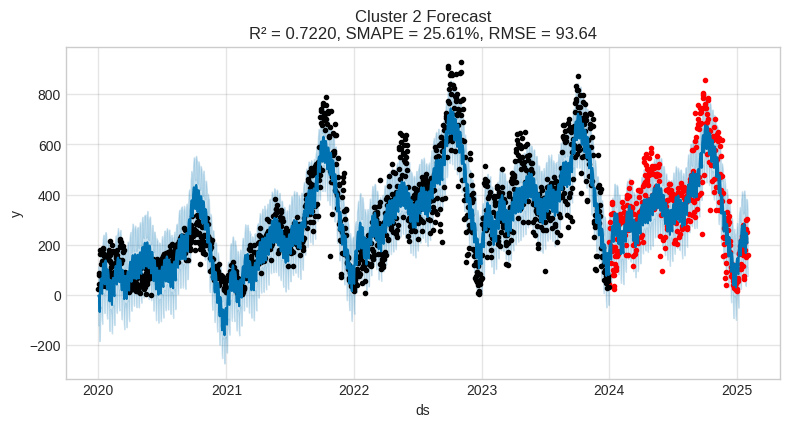

Cluster 2 Metrics:
  R-squared: 0.7220
  SMAPE: 25.61%
  MAPE: 39.71%
  RMSE: 93.64
  MPE: -0.22%
-----------------------------------


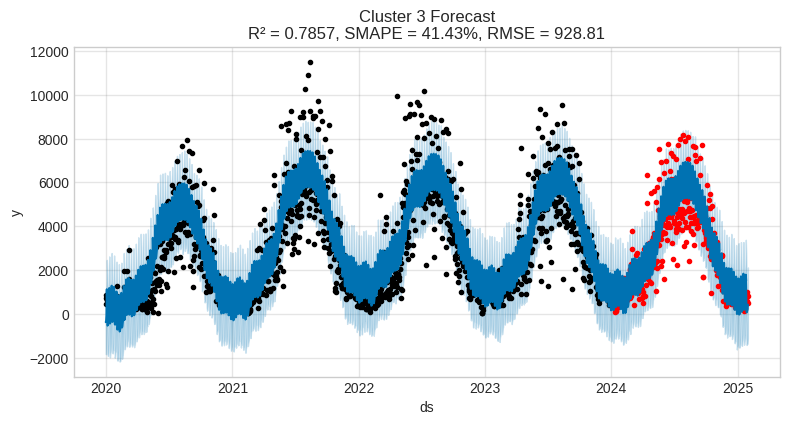

Cluster 3 Metrics:
  R-squared: 0.7857
  SMAPE: 41.43%
  MAPE: 46.45%
  RMSE: 928.81
  MPE: -0.11%
-----------------------------------


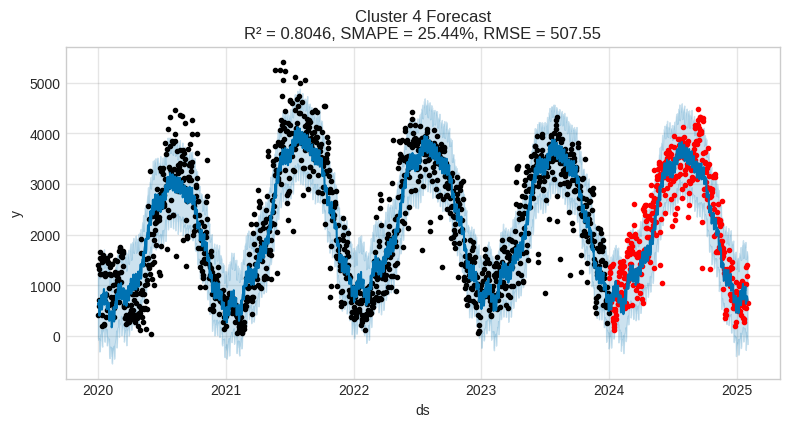

Cluster 4 Metrics:
  R-squared: 0.8046
  SMAPE: 25.44%
  MAPE: 29.82%
  RMSE: 507.55
  MPE: -0.06%
-----------------------------------


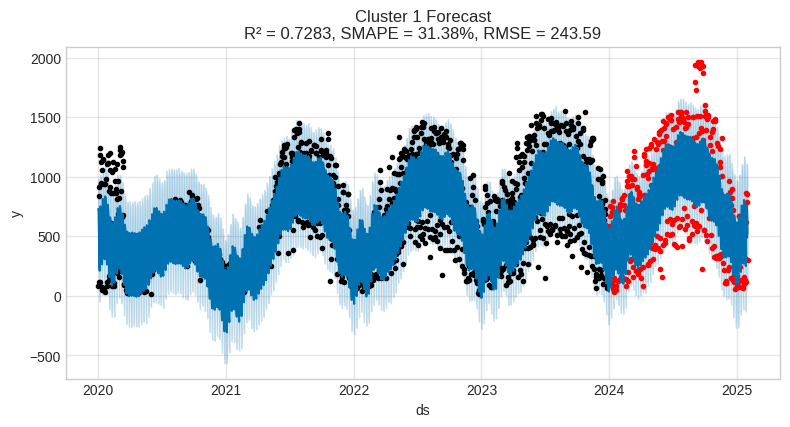

Cluster 1 Metrics:
  R-squared: 0.7283
  SMAPE: 31.38%
  MAPE: 50.22%
  RMSE: 243.59
  MPE: -0.34%
-----------------------------------


In [ ]:
from prophet import Prophet
import warnings
warnings.filterwarnings("ignore")
import logging
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# Suppress Prophet and cmdstanpy logging
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

# Create dictionaries to store different metrics
cluster_errors = {}
cluster_r2_scores = {}
cluster_smape_scores = {}
cluster_mape_scores = {}
cluster_rmse_scores = {}

# Function to calculate SMAPE (Symmetric Mean Absolute Percentage Error)
def calculate_smape(actual, forecast):
    return 100 * np.mean(2 * np.abs(forecast - actual) / (np.abs(actual) + np.abs(forecast)))

# Function to calculate RMSE (Root Mean Squared Error)
def calculate_rmse(actual, forecast):
    return np.sqrt(np.mean((forecast - actual) ** 2))

for cluster in stations_with_clusters["cluster"].unique():
    y_train_cluster = cluster_series_df.loc[cluster_series_df["cluster"] == cluster].reset_index().rename(columns={"date": "ds", "total_rides": "y"})
    y_test_cluster = test_cluster_df.loc[test_cluster_df["cluster"] == cluster].reset_index().rename(columns={"date": "ds", "total_rides": "y"})
    y_test_cluster["ds"] = pd.to_datetime(y_test_cluster["ds"])

    model = Prophet()

    try:
        # Fit the model
        model.fit(y_train_cluster)

        # Make future predictions
        future_data = model.make_future_dataframe(periods=len(y_test_cluster), freq='d')
        forecast_data = model.predict(future_data)

        # Merge forecast with actual test values
        merge_forecast = forecast_data.merge(y_test_cluster, on="ds")

        # Calculate MPE (Mean Percentage Error)
        merge_forecast["MPE"] = (merge_forecast.y - merge_forecast.yhat) / merge_forecast.y

        # Extract test period predictions (last 'n' days)
        test_predictions = merge_forecast.tail(len(y_test_cluster))

        # Calculate R-squared
        r2 = r2_score(test_predictions.y, test_predictions.yhat)

        # Calculate SMAPE
        smape = calculate_smape(test_predictions.y, test_predictions.yhat)

        # Calculate MAPE (Mean Absolute Percentage Error)
        mape = np.mean(np.abs((test_predictions.y - test_predictions.yhat) / test_predictions.y)) * 100

        # Calculate RMSE
        rmse = calculate_rmse(test_predictions.y, test_predictions.yhat)

        # Store metrics
        cluster_errors[cluster] = merge_forecast["MPE"].mean()
        cluster_r2_scores[cluster] = r2
        cluster_smape_scores[cluster] = smape
        cluster_mape_scores[cluster] = mape
        cluster_rmse_scores[cluster] = rmse

        # Plot the results
        p = model.plot(forecast_data, figsize=(8,4))
        plt.scatter(pd.to_datetime(y_test_cluster.ds), pd.to_numeric(y_test_cluster.y), color='r', marker='.')
        plt.title(f"Cluster {cluster} Forecast\nR² = {r2:.4f}, SMAPE = {smape:.2f}%, RMSE = {rmse:.2f}")
        plt.show()

        # Print metrics summary for this cluster
        print(f"Cluster {cluster} Metrics:")
        print(f"  R-squared: {r2:.4f}")
        print(f"  SMAPE: {smape:.2f}%")
        print(f"  MAPE: {mape:.2f}%")
        print(f"  RMSE: {rmse:.2f}")
        print(f"  MPE: {cluster_errors[cluster]:.2f}%")
        print("-----------------------------------")

    except Exception as e:
        print(f"Cluster {cluster} failed to train. Error: {str(e)}")

# Create a DataFrame with all metrics for comparison
metrics_df = pd.DataFrame({
    'Cluster': list(cluster_errors.keys()),
    'R-squared': [cluster_r2_scores.get(c, np.nan) for c in cluster_errors.keys()],
    'SMAPE (%)': [cluster_smape_scores.get(c, np.nan) for c in cluster_errors.keys()],
    'MAPE (%)': [cluster_mape_scores.get(c, np.nan) for c in cluster_errors.keys()],
    'RMSE': [cluster_rmse_scores.get(c, np.nan) for c in cluster_errors.keys()],
    'MPE (%)': [cluster_errors.get(c, np.nan) for c in cluster_errors.keys()]
})